# adaptive bond rank の DMRG-like 学習

この Notebook は `07_fixed_rank_sweep_and_pareto.ipynb` の Fashion-MNIST MLP、tensorization、データ分割、DMRG-like の更新と early stopping を使い、bond rank だけを更新後の discarded weight で選ぶ。

主張できるのは、この固定 seed・tensorization・学習条件で、adaptive DMRG-like の 3 閾値が 07 の固定 rank 候補集合の精度・parameter 数・理論 MACs の交換関係を改善したか、までである。DMRG-like 更新が一般に通常 TT より優れる、とは結論しない。非一様 rank を固定した通常 Adam 対照と追加 seed は、08 が有望だった場合の次段階であり、ここでは追加しない。

`RUN_MAIN_EXPERIMENT` の既定値は偽である。上から実行しても 3 閾値の長時間学習は始まらない。


In [23]:
import csv
import hashlib
import json
import math
import os
import random
import time
from pathlib import Path

os.environ.setdefault("KMP_DUPLICATE_LIB_OK", "TRUE")

import matplotlib

matplotlib.use("Agg")
import matplotlib.pyplot as plt
from matplotlib import font_manager
import numpy as np
import pandas as pd
import torch
from torch import nn
from torch.utils.data import DataLoader, TensorDataset

from nn_compression.compression import TTLinear
from nn_compression.datasets import get_fashion_mnist_datasets, split_fashion_mnist_dataset
from nn_compression.metrics import (
    count_parameters,
    linear_macs,
    measure_synchronized_inference_latency,
    tt_linear_direct_contraction_macs,
)
from nn_compression.metrics.evaluation import evaluate
from nn_compression.models import MNISTMLP
from nn_compression.selection import extract_pareto_frontier
from nn_compression.training import (
    GpuResidentTensorBatches,
    NonFiniteLocalUpdate,
    initial_validation_selection,
    replay_validation_selection,
    update_tt_linear_two_core_pair,
    update_validation_selection,
)
from nn_compression.tt_mps import (
    tt_matrix_canonicality_errors,
    tt_matrix_ranks,
)
from nn_compression.utils import find_project_root, set_seed

for font_name in ("Yu Gothic", "Meiryo", "MS Gothic"):
    if any(font_name == font.name for font in font_manager.fontManager.ttflist):
        plt.rcParams["font.family"] = font_name
        break
plt.rcParams["axes.unicode_minus"] = False
plt.ioff()

RUN_PRECHECK = False
RUN_SMOKE = False
RUN_MAIN_EXPERIMENT = False
RUN_UNIT_TESTS = False
RUN_EVALUATE_BEST = True
MEASURE_LATENCY = True
REGENERATE_DISPLAY_ARTIFACTS = False

SEED = 0
OUT_MODES = (4, 2, 2, 2, 4, 4)
IN_MODES = (2, 2, 2, 2, 7, 7)
RANK12_REFERENCE_RANKS = (1, 8, 12, 12, 12, 12, 1)
MIN_BOND_RANK = 1
MAX_BOND_RANK = 12
DISCARDED_WEIGHT_THRESHOLDS = (1e-6, 1e-4, 1e-2)
THRESHOLD_DIRECTORIES = {1e-6: "threshold_1e-06", 1e-4: "threshold_1e-04", 1e-2: "threshold_1e-02"}
MIN_DELTA = 1e-4
PATIENCE = 5
SPLIT_LENGTHS = (50_000, 5_000, 5_000)
TARGET_LAYER = "fc1"
INITIAL_MAX_SWEEPS = 200
DMRG_TT_LEARNING_RATE = 0.3
DMRG_DENSE_LEARNING_RATE = 0.3
DMRG_BATCH_SIZE = 4096
LOCAL_STEPS_PER_PAIR = 8
VALIDATION_BATCH_SIZE = 512
TRAINING_DIAGNOSTIC_BATCH_SIZE = 512
CANONICALITY_AUDIT_INTERVAL = 80
CANONICALITY_TOLERANCE = 1e-4
LATENCY_BATCH_SIZES = (1, 4096)
LATENCY_WARMUP = 20
LATENCY_REPETITIONS = 100
SMOKE_THRESHOLD = 1e-4
SMOKE_SAMPLES = 32
NOTEBOOK06_SPLIT_INDEX_SHA256 = (
    "aaed0a23690e2e3c0fd3b21c21ec28adb2606b17941b98087503382c3372f913"
    "|12cf7fe6cc2cdbb43177107c8a30dffb86cc099386d61fa5f4f05fdb1795d360"
    "|a80ccd6c95a3aa08fcfb7a5a10ffc883344da48ec37ce605220f964cef14cb26"
)
NOTEBOOK06_IMAGE_SHA256 = "6a1fd0602db5a1066210a55375d18f9b12115269e7c6759f64504735f020d4d5"
NOTEBOOK06_LABEL_SHA256 = "6ead6f3f16028865d36fd3c8625eba751820bd8031265a3be03e206136a3c96c"
NOTEBOOK06_STAGE_C_SHA256 = "ef9d5afcbffc0cdad787bc7e17f230917ae7cfb780bd506f5a348ae38ce10c6a"
EXPERIMENT_NAME = "08_adaptive_bond_rank_dmrg_like_pareto"
SMOKE_EXPERIMENT_NAME = "08_adaptive_bond_rank_dmrg_like_pareto_smoke"
NOTEBOOK07_EXPERIMENT = "07_fixed_rank_sweep_and_pareto_gpu_slice"

project_root = find_project_root(Path.cwd())
NOTEBOOK_PATH = (
    project_root
    / "notebooks"
    / "40_dmrg"
    / "10_fashion_mnist_mlp"
    / "08_adaptive_bond_rank_dmrg_like_pareto.ipynb"
)
STAGE_C_PATH = (
    project_root
    / "models"
    / "40_dmrg"
    / "10_fashion_mnist_mlp"
    / "01_tt_initialization_scale_diagnostics"
    / "initial_stage_c.pt"
)
MODELS_DIR = project_root / "models" / "40_dmrg" / "10_fashion_mnist_mlp" / EXPERIMENT_NAME
RESULTS_DIR = project_root / "results" / "40_dmrg" / "10_fashion_mnist_mlp" / EXPERIMENT_NAME
NOTEBOOK07_RESULTS = project_root / "results" / "40_dmrg" / "10_fashion_mnist_mlp" / NOTEBOOK07_EXPERIMENT
print("project:", project_root)
print("RUN_PRECHECK", RUN_PRECHECK)
print("RUN_SMOKE", RUN_SMOKE)
print("RUN_MAIN_EXPERIMENT", RUN_MAIN_EXPERIMENT)
print("RUN_EVALUATE_BEST", RUN_EVALUATE_BEST)
print("MEASURE_LATENCY", MEASURE_LATENCY)
print("CANONICALITY_TOLERANCE", CANONICALITY_TOLERANCE)


project: D:\dev\nn-compression-svd-dmrg
RUN_PRECHECK False
RUN_SMOKE False
RUN_MAIN_EXPERIMENT False
RUN_EVALUATE_BEST True
MEASURE_LATENCY True
CANONICALITY_TOLERANCE 0.0001


## 共通初期状態

使う checkpoint は、07 が rank 12 の学習前 Stage C として照合している `models/40_dmrg/10_fashion_mnist_mlp/01_tt_initialization_scale_diagnostics/initial_stage_c.pt` である。Notebook 06 の学習済み DMRG-like best ではない。

ファイル内の `stage` が `C` で、actual ranks が $(1, 8, 12, 12, 12, 12, 1)$、SHA-256 が 07 の `NOTEBOOK06_STAGE_C_SHA256` と一致するときだけ先へ進む。一致しなければ別の checkpoint へは置き換えない。

データ分割は train 50,000、early-stopping validation 5,000、rank-selection validation 5,000、seed 0。test は長さ確認のあと破棄し、学習・閾値選択・checkpoint 選択に使わない。


In [33]:
def file_sha256(path):
    digest = hashlib.sha256()
    with Path(path).open("rb") as handle:
        for chunk in iter(lambda: handle.read(1 << 20), b""):
            digest.update(chunk)
    return digest.hexdigest()

def tensor_sha256(tensor):
    array = tensor.detach().contiguous().cpu().numpy()
    return hashlib.sha256(array.tobytes()).hexdigest()

def index_sha256(subset):
    indices = torch.tensor(list(subset.indices), dtype=torch.int64)
    return hashlib.sha256(indices.numpy().tobytes()).hexdigest()

def atomic_write_bytes(path, writer):
    path = Path(path)
    path.parent.mkdir(parents=True, exist_ok=True)
    temporary = path.with_name(f"{path.stem}.{os.getpid()}.tmp{path.suffix}")
    writer(temporary)
    # Windows では AV / Indexer が宛先を掴んでいると os.replace が WinError 5 になることがある。
    last_error = None
    for attempt in range(12):
        try:
            os.replace(temporary, path)
            return
        except PermissionError as error:
            last_error = error
            time.sleep(0.05 * (attempt + 1))
    raise last_error

def atomic_torch(path, payload):
    atomic_write_bytes(path, lambda temporary: torch.save(payload, temporary))

def atomic_text(path, text):
    atomic_write_bytes(path, lambda temporary: Path(temporary).write_text(text, encoding="utf-8"))

def atomic_json(path, payload):
    atomic_text(path, json.dumps(payload, ensure_ascii=False, indent=2, sort_keys=True) + "\n")

def cell_text(value):
    if value is None:
        return ""
    if isinstance(value, float):
        return repr(value)
    if isinstance(value, bool):
        return "True" if value else "False"
    if isinstance(value, (tuple, list)):
        return "|".join(str(item) for item in value)
    return str(value)

def atomic_csv(path, fieldnames, rows):
    def writer(temporary):
        with Path(temporary).open("w", encoding="utf-8", newline="") as handle:
            csv_writer = csv.DictWriter(handle, fieldnames=fieldnames, extrasaction="raise")
            csv_writer.writeheader()
            for row in rows:
                csv_writer.writerow({name: cell_text(row.get(name)) for name in fieldnames})

    atomic_write_bytes(path, writer)

def read_csv_rows(path):
    with Path(path).open(encoding="utf-8", newline="") as handle:
        return list(csv.DictReader(handle))

def parse_float(value):
    if value is None or value == "":
        return None
    return float(value)

def parse_int(value):
    if value is None or value == "":
        return None
    return int(value)

def ranks_text(ranks):
    return "|".join(str(int(rank)) for rank in ranks)

def parse_ranks(text):
    if text is None or text == "":
        return None
    return tuple(int(part) for part in str(text).split("|"))

def actual_ranks_of(model):
    return tuple(int(rank) for rank in tt_matrix_ranks(list(model.fc1.cores)))

def clone_state(model):
    return {key: value.detach().cpu().clone() for key, value in model.state_dict().items()}

def model_from_checkpoint(path, device):
    payload = torch.load(path, map_location="cpu", weights_only=False)
    state = payload["state_dict"]
    cores = [state[f"fc1.cores.{index}"] for index in range(len(OUT_MODES))]
    model = MNISTMLP()
    model.fc1 = TTLinear(cores, OUT_MODES, IN_MODES, bias=state["fc1.bias"])
    model.load_state_dict(state)
    model.to(device)
    return model, payload

def core_elements_of(model):
    return int(sum(core.numel() for core in model.fc1.cores))

def fc1_parameters_of(model):
    return int(sum(parameter.numel() for name, parameter in model.named_parameters() if name.startswith("fc1.")))

def theoretical_macs_of(model):
    if isinstance(model.fc1, TTLinear):
        fc1 = int(sum(tt_linear_direct_contraction_macs(OUT_MODES, IN_MODES, actual_ranks_of(model))))
    else:
        fc1 = int(linear_macs(model.fc1))
    total = fc1 + int(linear_macs(model.fc2)) + int(linear_macs(model.fc3))
    return fc1, total

def notebook_code_sha256():
    notebook = json.loads(NOTEBOOK_PATH.read_text(encoding="utf-8"))
    excluded = {
        "INITIAL_MAX_SWEEPS",
        "RUN_PRECHECK",
        "RUN_SMOKE",
        "RUN_MAIN_EXPERIMENT",
        "RUN_UNIT_TESTS",
        "RUN_EVALUATE_BEST",
        "MEASURE_LATENCY",
        "REGENERATE_DISPLAY_ARTIFACTS",
    }
    chunks = []
    for cell in notebook["cells"]:
        if cell.get("cell_type") != "code":
            continue
        source = cell.get("source", "")
        if isinstance(source, list):
            source = "".join(source)
        kept = []
        for line in source.replace("\r\n", "\n").split("\n"):
            stripped = line.strip()
            name = stripped.split("=", 1)[0].strip()
            if name in excluded:
                continue
            kept.append(line)
        chunks.append("\n".join(kept))
    return hashlib.sha256("\n\n".join(chunks).encode("utf-8")).hexdigest()

def make_loader(dataset, batch_size, *, shuffle=False, generator=None):
    return DataLoader(
        dataset,
        batch_size=batch_size,
        shuffle=shuffle,
        generator=generator,
        drop_last=False,
        num_workers=0,
        pin_memory=False,
    )

def capture_rng_state():
    state = {
        "python": random.getstate(),
        "numpy": np.random.get_state(),
        "torch": torch.get_rng_state(),
    }
    if torch.cuda.is_available():
        state["cuda"] = torch.cuda.get_rng_state_all()
    return state

def restore_rng_state(state):
    random.setstate(state["python"])
    np.random.set_state(state["numpy"])
    torch_state = state["torch"].detach().cpu() if torch.is_tensor(state["torch"]) else state["torch"]
    torch.set_rng_state(torch_state)
    if "cuda" in state and torch.cuda.is_available():
        cuda_states = []
        for tensor in state["cuda"]:
            if torch.is_tensor(tensor):
                tensor = tensor.detach().to(dtype=torch.uint8, device="cpu").contiguous()
            cuda_states.append(tensor)
        torch.cuda.set_rng_state_all(cuda_states)

def synchronize(device):
    if device.type == "cuda":
        torch.cuda.synchronize(device)

def round_trip_visits(n_cores):
    right = [(index, "right") for index in range(n_cores - 1)]
    left = [(index, "left") for index in range(n_cores - 2, -1, -1)]
    return right + left

def load_active_generation(directory):
    directory = Path(directory)
    pointer_path = directory / "active_generation.json"
    partial = sorted(path.name for path in directory.glob(".partial_generation_*"))
    legacy = [
        name for name in ("history.csv", "run_state.json", "final_model.pt", "config.json", "best_model.pt", "adam_training_state.pt")
        if (directory / name).is_file()
    ]
    if not pointer_path.is_file():
        if legacy or partial:
            raise RuntimeError(
                "保存世代の pointer がありません。旧形式または不完全な保存は自動採用せず、上書きもしません: "
                f"{directory} legacy={legacy} partial={partial}"
            )
        return None
    pointer = json.loads(pointer_path.read_text(encoding="utf-8"))
    artifact = directory / pointer["directory"]
    manifest_path = artifact / "manifest.json"
    if not manifest_path.is_file():
        raise RuntimeError(f"有効世代の manifest がありません: {artifact}")
    manifest = json.loads(manifest_path.read_text(encoding="utf-8"))
    if int(manifest["generation"]) != int(pointer["generation"]):
        raise RuntimeError("active_generation と manifest の世代が一致しません。")
    for name, digest in manifest["files"].items():
        file_path = artifact / name
        if not file_path.is_file() or file_sha256(file_path) != digest:
            raise RuntimeError(f"世代 {pointer['generation']} の {name} が manifest と一致しないため採用しません。")
    initial_path = directory / "initial_model.pt"
    if not initial_path.is_file() or file_sha256(initial_path) != manifest["initial_model_sha256"]:
        raise RuntimeError("条件の initial_model.pt が世代 manifest と一致しません。")
    if "rank_initial_sha256" not in manifest:
        raise RuntimeError("manifest に rank initial の hash がありません。自動採用しません。")
    return {"path": artifact, "manifest": manifest, "pointer": pointer}

def read_generation_state(directory):
    active = load_active_generation(directory)
    if active is None:
        raise RuntimeError(f"有効な保存世代がありません: {directory}")
    return json.loads((active["path"] / "run_state.json").read_text(encoding="utf-8"))

def publish_generation(directory, config, environment, run_state, history, local_rows, payloads, adam_state, write_initial, rng_payload, source_initial_path):
    directory = Path(directory)
    directory.mkdir(parents=True, exist_ok=True)
    if "initial_model_sha256" not in config:
        raise RuntimeError("config に initial_model_sha256 が無いため保存しません。")
    lock_path = directory / ".publish_lock"
    try:
        lock_fd = os.open(lock_path, os.O_CREAT | os.O_EXCL | os.O_WRONLY)
    except FileExistsError as error:
        raise RuntimeError(
            "同じ条件への並行保存には対応していません。.publish_lock があるため保存を拒否します: "
            + str(directory)
        ) from error
    try:
        os.write(lock_fd, str(os.getpid()).encode("ascii"))
        os.close(lock_fd)
        if write_initial:
            target = directory / "initial_model.pt"
            if target.is_file():
                raise RuntimeError(f"initial_model.pt は既にあるため再保存しません: {target}")
            shutil.copyfile(source_initial_path, target)
        initial_sha = file_sha256(directory / "initial_model.pt")
        if initial_sha != config["initial_model_sha256"] or initial_sha != file_sha256(source_initial_path):
            raise RuntimeError("条件の initial が rank 共通 initial と一致しません。")
        pointer_path = directory / "active_generation.json"
        used = set()
        if pointer_path.is_file():
            used.add(int(json.loads(pointer_path.read_text(encoding="utf-8"))["generation"]))
        for existing in directory.iterdir():
            name = existing.name
            if name.startswith("generation_") and name.removeprefix("generation_").split("_", 1)[0].isdigit():
                used.add(int(name.removeprefix("generation_").split("_", 1)[0]))
            elif name.startswith(".partial_generation_"):
                token = name.removeprefix(".partial_generation_").split("_", 1)[0]
                if token.isdigit():
                    used.add(int(token))
        generation = max(used, default=0) + 1
        final = directory / f"generation_{generation:06d}"
        if final.is_dir():
            raise RuntimeError(f"未使用であるはずの世代ディレクトリが既にあるため保存しません: {final}")
        partial = directory / f".partial_generation_{generation:06d}_{os.getpid()}_{time.time_ns()}"
        if partial.exists():
            raise RuntimeError(f"一時ディレクトリ名が衝突したため、既存の一時ディレクトリは削除せず停止します: {partial}")
        partial.mkdir()
        started = time.perf_counter()
        atomic_torch(partial / "best_model.pt", payloads["best"])
        atomic_torch(partial / "final_model.pt", payloads["final"])
        atomic_csv(partial / "history.csv", HISTORY_FIELDS, history)
        names = ["best_model.pt", "final_model.pt", "history.csv"]
        if local_rows is not None:
            if rng_payload is None:
                raise RuntimeError("DMRG-like の保存に RNG と中心の記録がありません。")
            atomic_csv(partial / "local_updates.csv", LOCAL_FIELDS, local_rows)
            atomic_torch(partial / "dmrg_rng_state.pt", rng_payload)
            names.extend(["local_updates.csv", "dmrg_rng_state.pt"])
        if adam_state is not None:
            atomic_torch(partial / "adam_training_state.pt", adam_state)
            names.append("adam_training_state.pt")
        atomic_json(partial / "config.json", config)
        atomic_json(partial / "environment.json", environment)
        names.extend(["config.json", "environment.json"])
        run_state["seconds_save"] = float(run_state["seconds_save"]) + (time.perf_counter() - started)
        atomic_json(partial / "run_state.json", run_state)
        names.append("run_state.json")
        manifest = {
            "generation": generation,
            "completed_epochs": run_state["completed_epochs"],
            "completed_sweeps": run_state["completed_sweeps"],
            "optimizer_steps": run_state["optimizer_steps"],
            "total_local_updates": run_state["total_local_updates"],
            "history_rows": run_state["history_rows"],
            "center": run_state.get("center"),
            "stop_reason": run_state["stop_reason"],
            "initial_model_sha256": initial_sha,
            "rank_initial_sha256": config["initial_model_sha256"],
            "files": {name: file_sha256(partial / name) for name in names},
        }
        atomic_json(partial / "manifest.json", manifest)
        for name, digest in manifest["files"].items():
            if file_sha256(partial / name) != digest:
                raise RuntimeError(f"公開前の manifest 検証に失敗したため pointer は切り替えません: {name}")
        pointer = {
            "generation": manifest["generation"],
            "directory": final.name,
            "completed_epochs": manifest["completed_epochs"],
            "completed_sweeps": manifest["completed_sweeps"],
            "optimizer_steps": manifest["optimizer_steps"],
            "total_local_updates": manifest["total_local_updates"],
            "stop_reason": manifest["stop_reason"],
        }
        for key in ("completed_epochs", "completed_sweeps", "optimizer_steps", "total_local_updates", "stop_reason"):
            if pointer[key] != run_state[key] or pointer[key] != manifest[key]:
                raise RuntimeError(f"pointer の {key} が公開する世代と一致しないため切り替えません。")
        os.replace(partial, final)
        atomic_json(pointer_path, pointer)
        return final
    finally:
        if lock_path.exists():
            lock_path.unlink()

def selection_from_history(rows, step_name):
    losses = [float(row["early_stopping_validation_loss"]) for row in rows]
    steps = [int(row[step_name]) for row in rows]
    states = replay_validation_selection(losses, steps, min_delta=MIN_DELTA, patience=PATIENCE)
    last = states[-1]
    recorded = rows[-1]
    if (
        float(recorded["strict_best_loss"]) != last.strict_best_loss
        or int(recorded["strict_best_step"]) != last.strict_best_step
        or float(recorded["reference_loss"]) != last.reference_loss
        or int(recorded["non_improvement_count"]) != last.non_improvement_count
        or (recorded["early_stop_triggered"] == "True") != last.early_stop_triggered
    ):
        raise RuntimeError("history の選択状態が validation selection の再生と一致しません。")
    return last

def history_row(state_name, model, selection, *, epoch, sweep, updates, train_loss, train_accuracy, validation_loss, validation_accuracy, became_best, seconds):
    fc1_macs, total_macs = theoretical_macs_of(model)
    return {
        "state": state_name,
        "epoch": epoch,
        "sweep": sweep,
        "cumulative_local_updates": updates,
        "train_loss": train_loss,
        "train_accuracy": train_accuracy,
        "early_stopping_validation_loss": validation_loss,
        "early_stopping_validation_accuracy": validation_accuracy,
        "strict_best_loss": selection.strict_best_loss,
        "strict_best_step": selection.strict_best_step,
        "reference_loss": selection.reference_loss,
        "non_improvement_count": selection.non_improvement_count,
        "early_stop_triggered": selection.early_stop_triggered,
        "became_strict_best": became_best,
        "actual_ranks": ranks_text(actual_ranks_of(model)),
        "tt_core_elements": core_elements_of(model),
        "fc1_parameters": fc1_parameters_of(model),
        "total_parameters": int(count_parameters(model)),
        "theoretical_fc1_macs": fc1_macs,
        "theoretical_total_macs": total_macs,
        "cumulative_train_seconds": seconds["train"],
        "cumulative_eval_seconds": seconds["eval"],
        "cumulative_save_seconds": seconds["save"],
    }

def evaluate_early(model, dataset, device):
    criterion = nn.CrossEntropyLoss(reduction="mean")
    synchronize(device)
    started = time.perf_counter()
    loss, accuracy = evaluate(model, make_loader(dataset, VALIDATION_BATCH_SIZE), criterion, device)
    synchronize(device)
    return float(loss), float(accuracy), time.perf_counter() - started

import copy
import inspect
import shutil

import nn_compression.tt_mps.matrix_two_site as _bond_rank_module

HISTORY_FIELDS = [
    "state",
    "epoch",
    "sweep",
    "cumulative_local_updates",
    "train_loss",
    "train_accuracy",
    "early_stopping_validation_loss",
    "early_stopping_validation_accuracy",
    "strict_best_loss",
    "strict_best_step",
    "reference_loss",
    "non_improvement_count",
    "early_stop_triggered",
    "became_strict_best",
    "actual_ranks",
    "tt_core_elements",
    "fc1_parameters",
    "total_parameters",
    "theoretical_fc1_macs",
    "theoretical_total_macs",
    "cumulative_train_seconds",
    "cumulative_eval_seconds",
    "cumulative_save_seconds",
    "max_canonicality_error",
    "canonicality_center",
    "canonicality_update",
    "canonicality_tolerance",
]

LOCAL_FIELDS = [
    "cumulative_updates",
    "sweep",
    "pair_index",
    "target_bond",
    "direction",
    "local_step",
    "rank_before",
    "available_rank",
    "threshold_required_rank",
    "retained_rank",
    "relative_discarded_weight",
    "threshold_satisfied",
    "cap_limited",
    "min_rank_limited",
    "zero_spectrum",
    "actual_ranks",
    "center_before",
    "center_after",
    "diagnostic_batch_loss",
    "update_seconds",
    "canonicality_error",
    "canonicality_center",
    "status",
]

VOLATILE_CONFIG_KEYS = frozenset({"notebook_code_sha256", "implementation_sha256"})
SHARED = None


LEARNING_HASH_INCLUDED = (
    "select_bond_rank_from_singular_values",
    "split_merged_tt_matrix",
    "split_merged_tt_matrix_by_discarded_weight",
    "canonicalize_tt_matrix_cores",
    "update_tt_linear_two_core_pair",
    "accumulate_tt_linear_pair_full_batch_gradients",
    "_full_batch_samples",
    "GpuResidentTensorBatches.batches",
    "initial_validation_selection",
    "update_validation_selection",
    "replay_validation_selection",
    "split_fashion_mnist_dataset",
    "train_adaptive",
    "round_trip_visits",
)
LEARNING_HASH_EXCLUDED = (
    "display_comparison",
    "_scatter_cost",
    "_show_figure",
    "evaluate_saved_bests",
    "notebook_code_sha256",
)



def notebook_function_source(name):
    """Notebook ファイルから関数本文を読む。kernel の cell 実行状態には依存しない。"""
    import ast
    notebook = json.loads(NOTEBOOK_PATH.read_text(encoding="utf-8"))
    for cell in notebook["cells"]:
        if cell.get("cell_type") != "code":
            continue
        cell_source = cell.get("source", "")
        if isinstance(cell_source, list):
            cell_source = "".join(cell_source)
        module = ast.parse(cell_source)
        lines = cell_source.splitlines()
        for node in module.body:
            if isinstance(node, ast.FunctionDef) and node.name == name:
                return "\n".join(lines[node.lineno - 1 : node.end_lineno])
    raise RuntimeError(name + " のソースを Notebook から読めません。")


def implementation_sha256():
    """学習結果に効く実装だけを hash する。作図と事後評価は除外する。"""
    import nn_compression.datasets.fashion_mnist as fashion_module
    import nn_compression.training.gpu_resident_batches as resident_module
    import nn_compression.training.tt_linear_full_batch_sweep as sweep_module
    import nn_compression.training.validation_selection as selection_module

    pieces = [
        ("select_bond_rank_from_singular_values", _bond_rank_module.select_bond_rank_from_singular_values),
        ("split_merged_tt_matrix", _bond_rank_module.split_merged_tt_matrix),
        ("split_merged_tt_matrix_by_discarded_weight", _bond_rank_module.split_merged_tt_matrix_by_discarded_weight),
        ("canonicalize_tt_matrix_cores", _bond_rank_module.canonicalize_tt_matrix_cores),
        ("update_tt_linear_two_core_pair", sweep_module.update_tt_linear_two_core_pair),
        ("accumulate_tt_linear_pair_full_batch_gradients", sweep_module.accumulate_tt_linear_pair_full_batch_gradients),
        ("_full_batch_samples", sweep_module._full_batch_samples),
        ("GpuResidentTensorBatches.batches", resident_module.GpuResidentTensorBatches.batches),
        ("initial_validation_selection", selection_module.initial_validation_selection),
        ("update_validation_selection", selection_module.update_validation_selection),
        ("replay_validation_selection", selection_module.replay_validation_selection),
        ("split_fashion_mnist_dataset", fashion_module.split_fashion_mnist_dataset),
    ]
    names = [name for name, _piece in pieces] + ["train_adaptive", "round_trip_visits"]
    if tuple(names) != LEARNING_HASH_INCLUDED:
        raise RuntimeError("学習 hash の対象が宣言と違います: " + str(names))
    chunks = [inspect.getsource(piece) for _name, piece in pieces]
    chunks.append(notebook_function_source("train_adaptive"))
    chunks.append(notebook_function_source("round_trip_visits"))
    chunks.append(
        repr(
            (
                SEED,
                MIN_BOND_RANK,
                MAX_BOND_RANK,
                DMRG_TT_LEARNING_RATE,
                DMRG_DENSE_LEARNING_RATE,
                DMRG_BATCH_SIZE,
                LOCAL_STEPS_PER_PAIR,
                MIN_DELTA,
                PATIENCE,
                VALIDATION_BATCH_SIZE,
                CANONICALITY_AUDIT_INTERVAL,
                CANONICALITY_TOLERANCE,
                SPLIT_LENGTHS,
                OUT_MODES,
                IN_MODES,
            )
        )
    )
    return hashlib.sha256("\n".join(chunks).encode("utf-8")).hexdigest()


def refuse_resume_on_implementation_change(saved_hash, current_hash):
    if not isinstance(saved_hash, str) or saved_hash == "":
        raise RuntimeError("implementation_sha256 が無いため再開しません。")
    if saved_hash != current_hash:
        raise RuntimeError("学習実装の hash が違うため再開も再学習もしません。")


def checkpoint_payload(model):
    fc1_macs, total_macs = theoretical_macs_of(model)
    ranks = actual_ranks_of(model)
    return {
        "layer_name": TARGET_LAYER,
        "state_dict": clone_state(model),
        "out_modes": list(OUT_MODES),
        "in_modes": list(IN_MODES),
        "actual_ranks": list(ranks),
        "tt_core_elements": core_elements_of(model),
        "fc1_parameters": fc1_parameters_of(model),
        "total_parameters": int(count_parameters(model)),
        "theoretical_fc1_macs": fc1_macs,
        "theoretical_total_macs": total_macs,
    }


def environment_record(device):
    record = {
        "torch": torch.__version__,
        "cuda": torch.version.cuda,
        "gpu_name": "",
        "cudnn": None,
        "allow_tf32_matmul": None,
        "allow_tf32_cudnn": None,
        "cudnn_deterministic": None,
        "compile": False,
        "execution": "eager",
    }
    if device.type == "cuda":
        record.update(
            {
                "gpu_name": torch.cuda.get_device_name(device),
                "cudnn": int(torch.backends.cudnn.version()),
                "allow_tf32_matmul": bool(torch.backends.cuda.matmul.allow_tf32),
                "allow_tf32_cudnn": bool(torch.backends.cudnn.allow_tf32),
                "cudnn_deterministic": bool(torch.backends.cudnn.deterministic),
            }
        )
    return record


def comparable_config(config):
    return {key: value for key, value in config.items() if key not in VOLATILE_CONFIG_KEYS}


def threshold_name(threshold):
    return THRESHOLD_DIRECTORIES[float(threshold)]


def condition_directory(models_dir, threshold):
    return models_dir / threshold_name(threshold) / "adaptive_dmrg_like"


def adaptive_config(shared, threshold, max_sweeps):
    return {
        "state": "adaptive_dmrg_like",
        "threshold": float(threshold),
        "min_bond_rank": MIN_BOND_RANK,
        "max_bond_rank": MAX_BOND_RANK,
        "seed": SEED,
        "dtype": "float32",
        "out_modes": list(OUT_MODES),
        "in_modes": list(IN_MODES),
        "target_layer": TARGET_LAYER,
        "min_delta": MIN_DELTA,
        "patience": PATIENCE,
        "validation_batch_size": VALIDATION_BATCH_SIZE,
        "criterion": "mean_cross_entropy",
        "optimizer": "full_batch_joint_gd",
        "tt_learning_rate": DMRG_TT_LEARNING_RATE,
        "dense_parameter_learning_rate": DMRG_DENSE_LEARNING_RATE,
        "full_batch_chunk_size": DMRG_BATCH_SIZE,
        "data_residency": "gpu_resident",
        "gradient_batch_source": "gpu_resident_contiguous_slices",
        "local_steps_per_pair": LOCAL_STEPS_PER_PAIR,
        "updates_per_sweep": 80,
        "validation_timing": "completed_sweep",
        "max_sweeps": int(max_sweeps),
        "initial_actual_ranks": list(RANK12_REFERENCE_RANKS),
        "initial_checkpoint": str(STAGE_C_PATH.relative_to(project_root)).replace("\\", "/"),
        "stage_c_sha256": NOTEBOOK06_STAGE_C_SHA256,
        "split_index_sha256": shared["split_sha256"],
        "comparison_atol": 0.0,
        "comparison_rtol": 0.0,
        "training_time_definition": "局所更新の wall time の合計。評価、保存、既存 initial checkpoint の作成時間は含まない。",
        "canonicality_audit_interval_updates": CANONICALITY_AUDIT_INTERVAL,
        "notebook_code_sha256": notebook_code_sha256(),
        "implementation_sha256": implementation_sha256(),
    }


def verify_adaptive_generation(directory, state):
    active = load_active_generation(directory)
    artifact = active["path"]
    rows = read_csv_rows(artifact / "history.csv")
    if len(rows) != int(state["history_rows"]):
        raise RuntimeError(f"history 行数が run_state と一致しません: {directory}")
    if len(rows) != int(state["completed_sweeps"]) + 1:
        raise RuntimeError("history 行数が完了 sweep 境界と一致しません。")
    if int(state["total_local_updates"]) != int(state["completed_sweeps"]) * 80 or int(state["center"]) != 0:
        raise RuntimeError("再開境界は完了 sweep、中心 site 0、更新数 = sweep * 80 だけです。")
    local_rows = read_csv_rows(artifact / "local_updates.csv")
    if [int(row["cumulative_updates"]) for row in local_rows] != list(range(1, len(local_rows) + 1)):
        raise RuntimeError("局所更新番号が連続していません。")
    if len(local_rows) != int(state["total_local_updates"]):
        raise RuntimeError("局所更新の行数が run_state と一致しません。")
    for row in local_rows:
        ranks = parse_ranks(row["actual_ranks"])
        bond = int(row["target_bond"])
        if int(row["retained_rank"]) != ranks[bond]:
            raise RuntimeError("retained rank が更新後の bond と一致しません。")
        if row["status"] != "ok":
            raise RuntimeError("局所更新の status が ok ではありません。")
    saved_config = json.loads((artifact / "config.json").read_text(encoding="utf-8"))
    initial_payload = torch.load(directory / "initial_model.pt", map_location="cpu", weights_only=False)
    initial_cores = [initial_payload["state_dict"][f"fc1.cores.{index}"] for index in range(len(OUT_MODES))]
    initial_ranks = tuple(int(rank) for rank in tt_matrix_ranks(initial_cores))
    if initial_ranks != tuple(saved_config["initial_actual_ranks"]):
        raise RuntimeError("initial checkpoint の actual ranks が config と一致しません。")
    for name, state_key in (("best_model.pt", "best_actual_ranks"), ("final_model.pt", "actual_ranks")):
        payload = torch.load(artifact / name, map_location="cpu", weights_only=False)
        cores = [payload["state_dict"][f"fc1.cores.{index}"] for index in range(len(OUT_MODES))]
        ranks = tuple(int(rank) for rank in tt_matrix_ranks(cores))
        if ranks != parse_ranks(state[state_key]):
            raise RuntimeError(f"{name} の core shape が run_state の rank と一致しません。")
        if list(payload["actual_ranks"]) != list(ranks):
            raise RuntimeError(f"{name} の metadata rank が core shape と一致しません。")
    rng_state = torch.load(artifact / "dmrg_rng_state.pt", map_location="cpu", weights_only=False)
    if (
        int(rng_state["completed_sweeps"]) != int(state["completed_sweeps"])
        or int(rng_state["total_local_updates"]) != int(state["total_local_updates"])
        or int(rng_state["center"]) != int(state["center"])
    ):
        raise RuntimeError("RNG 記録の sweep、更新数、中心が run_state と一致しません。")


def directory_action(directory, config):
    directory = Path(directory)
    if not directory.exists():
        return "start", None, None
    active = load_active_generation(directory)
    if active is None:
        contents = [path.name for path in directory.iterdir()]
        raise RuntimeError(f"世代情報の無いディレクトリは上書きしません: {directory} contents={contents}")
    artifact = active["path"]
    manifest = active["manifest"]
    saved = json.loads((artifact / "config.json").read_text(encoding="utf-8"))
    state = json.loads((artifact / "run_state.json").read_text(encoding="utf-8"))
    for key in ("completed_sweeps", "total_local_updates", "history_rows", "stop_reason", "center"):
        if manifest.get(key) != state.get(key):
            raise RuntimeError(f"manifest と run_state の {key} が一致しません: {directory}")
    if set(comparable_config(saved)) != set(comparable_config(config)):
        raise RuntimeError(f"config のキーが一致しないため上書きしません: {directory}")
    changed = [
        key
        for key in comparable_config(config)
        if key != "max_sweeps" and comparable_config(saved)[key] != comparable_config(config)[key]
    ]
    if changed:
        raise RuntimeError(f"設定が一致しないため上書きしません: {directory} {changed}")
    if int(config["max_sweeps"]) < int(saved["max_sweeps"]):
        raise RuntimeError(f"安全上限を下げる再開はしません: {directory}")
    if (directory / "unresumable_stop.json").is_file():
        raise RuntimeError(
            "sweep 途中の異常停止が記録されているため、その系列は再開しません: " + str(directory)
        )
    saved_implementation = saved.get("implementation_sha256")
    refuse_resume_on_implementation_change(saved_implementation, implementation_sha256())
    verify_adaptive_generation(directory, state)
    status = state["stop_reason"]
    if status in {"non_finite", "out_of_memory", "invalid_singular_values"}:
        raise RuntimeError(f"{status} のディレクトリは上書きしません: {directory}")
    if status == "early_stopping" or (status == "max_sweeps" and int(config["max_sweeps"]) == int(saved["max_sweeps"])):
        return "skip", state, artifact
    if status in {"running", "max_sweeps"}:
        return "resume", state, artifact
    raise RuntimeError(f"再開できない stop_reason です: {directory} {status}")


def canonicality_max_error(model, center):
    errors = tt_matrix_canonicality_errors(list(model.fc1.cores), OUT_MODES, IN_MODES, int(center))
    values = [float(value) for value in errors["left"] + errors["right"]]
    if not values:
        return 0.0
    return max(values)


def canonicality_failure(error, tolerance):
    if not math.isfinite(error):
        return "non_finite"
    if float(error) > float(tolerance):
        return "tolerance"
    return ""


def audit_initial_state():
    global SHARED
    full_train, test_dataset = get_fashion_mnist_datasets(project_root / "data", download=False)
    train_dataset, early_dataset, rank_dataset = split_fashion_mnist_dataset(full_train, SPLIT_LENGTHS, seed=SEED)
    if (len(train_dataset), len(early_dataset), len(rank_dataset)) != SPLIT_LENGTHS:
        raise RuntimeError("分割サイズが 50,000 / 5,000 / 5,000 ではありません。")
    test_length = len(test_dataset)
    del test_dataset
    if test_length != 10_000:
        raise RuntimeError("test の長さが 10,000 ではありません。中身は使いません。")
    train_images = torch.stack([train_dataset[index][0] for index in range(len(train_dataset))])
    train_labels = torch.tensor([int(train_dataset[index][1]) for index in range(len(train_dataset))], dtype=torch.int64)
    image_sha = tensor_sha256(train_images)
    label_sha = tensor_sha256(train_labels)
    split_sha = "|".join(index_sha256(subset) for subset in (train_dataset, early_dataset, rank_dataset))
    stage_sha = file_sha256(STAGE_C_PATH)
    if image_sha != NOTEBOOK06_IMAGE_SHA256 or label_sha != NOTEBOOK06_LABEL_SHA256 or split_sha != NOTEBOOK06_SPLIT_INDEX_SHA256:
        raise RuntimeError("データ分割または画像 checksum が Notebook 07 の記録と一致しません。学習は開始しません。")
    if stage_sha != NOTEBOOK06_STAGE_C_SHA256:
        raise RuntimeError("Stage C checkpoint の SHA-256 が Notebook 07 の記録と一致しません。別の checkpoint には置換しません。")
    payload = torch.load(STAGE_C_PATH, map_location="cpu", weights_only=False)
    cores = [payload["state_dict"][f"fc1.cores.{index}"] for index in range(len(OUT_MODES))]
    ranks = tuple(int(rank) for rank in tt_matrix_ranks(cores))
    if ranks != RANK12_REFERENCE_RANKS:
        raise RuntimeError(f"Stage C の actual ranks が {RANK12_REFERENCE_RANKS} ではありません: {ranks}")
    initial_center = int(payload.get("canonical_center") or 0)
    initial_errors = tt_matrix_canonicality_errors(cores, OUT_MODES, IN_MODES, initial_center)
    initial_error = max([float(value) for value in initial_errors["left"] + initial_errors["right"]], default=0.0)
    initial_failure = canonicality_failure(initial_error, CANONICALITY_TOLERANCE)
    if initial_failure:
        raise RuntimeError(
            "初期 Stage C の正準形誤差が許容を満たしません。"
            f" failure={initial_failure} center={initial_center} error={initial_error} tolerance={CANONICALITY_TOLERANCE} ranks={ranks}"
        )
    if list(payload["out_modes"]) != list(OUT_MODES) or list(payload["in_modes"]) != list(IN_MODES):
        raise RuntimeError("Stage C の tensorization が 07 と一致しません。")
    if payload.get("stage") != "C":
        raise RuntimeError("checkpoint の stage が C ではありません。学習済み best へは置換しません。")
    for core in cores:
        if not torch.isfinite(core).all():
            raise RuntimeError("Stage C の core に有限でない値があります。")
    SHARED = {
        "train": train_dataset,
        "early": early_dataset,
        "rank": rank_dataset,
        "train_images": train_images,
        "train_labels": train_labels,
        "split_sha256": split_sha,
        "stage_sha256": stage_sha,
        "initial_ranks": ranks,
        "canonical_center": payload.get("canonical_center"),
        "initial_canonicality_error": initial_error,
        "rank_cap": payload.get("rank_cap"),
    }
    print("initial checkpoint:", STAGE_C_PATH)
    print("stage:", payload.get("stage"), "rank_cap:", payload.get("rank_cap"), "canonical_center:", payload.get("canonical_center"))
    print("actual ranks:", ranks)
    print("sha256:", stage_sha)
    print("split sha256:", split_sha)
    return SHARED


def local_record(update, model, *, sweep, pair_index, direction, local_step, rank_before, center_before, elapsed):
    decision = update.bond_rank_decision
    if decision is None:
        raise RuntimeError("adaptive 更新なのに bond rank の選択結果がありません。")
    return {
        "cumulative_updates": None,
        "sweep": sweep,
        "pair_index": pair_index,
        "target_bond": pair_index + 1,
        "direction": direction,
        "local_step": local_step,
        "rank_before": int(rank_before),
        "available_rank": int(decision.available_rank),
        "threshold_required_rank": int(decision.threshold_required_rank),
        "retained_rank": int(decision.retained_rank),
        "relative_discarded_weight": float(decision.relative_discarded_weight),
        "threshold_satisfied": bool(decision.threshold_satisfied),
        "cap_limited": bool(decision.cap_limited),
        "min_rank_limited": bool(decision.min_rank_limited),
        "zero_spectrum": bool(decision.zero_spectrum),
        "actual_ranks": ranks_text(actual_ranks_of(model)),
        "center_before": center_before,
        "center_after": int(update.center),
        "diagnostic_batch_loss": float(update.diagnostic_batch_loss),
        "update_seconds": elapsed,
        "canonicality_error": "",
        "canonicality_center": "",
        "status": "ok",
    }


def train_adaptive(shared, threshold, max_sweeps, resident, diagnostic_images, diagnostic_labels, device):
    directory = condition_directory(MODELS_DIR, threshold)
    config = adaptive_config(shared, threshold, max_sweeps)
    config["initial_model_sha256"] = file_sha256(STAGE_C_PATH)
    action, saved_state, artifact = directory_action(directory, config)
    if action == "skip":
        print(f"threshold {threshold}: skip {saved_state['stop_reason']}")
        return saved_state
    criterion = nn.CrossEntropyLoss(reduction="mean")
    environment = environment_record(device)
    visits = round_trip_visits(len(OUT_MODES))
    if len(visits) * LOCAL_STEPS_PER_PAIR != 80:
        raise RuntimeError("1 往復が 80 更新ではありません。07 の sweep 定義と違います。")
    if action == "start":
        model, _payload = model_from_checkpoint(STAGE_C_PATH, device)
        candidate = copy.deepcopy(model)
        history = []
        local_rows = []
        seconds = {"train": 0.0, "eval": 0.0, "save": 0.0}
        center = 0
        completed_sweeps = 0
        best_payload = checkpoint_payload(model)
        selection = None
        write_initial = True
        if device.type == "cuda":
            torch.cuda.reset_peak_memory_stats(device)
    else:
        model, _payload = model_from_checkpoint(artifact / "final_model.pt", device)
        candidate = copy.deepcopy(model)
        history = read_csv_rows(artifact / "history.csv")
        local_rows = read_csv_rows(artifact / "local_updates.csv")
        selection = selection_from_history(history, "cumulative_local_updates")
        seconds = {
            "train": float(saved_state["seconds_train"]),
            "eval": float(saved_state["seconds_eval"]),
            "save": float(saved_state["seconds_save"]),
        }
        center = int(saved_state["center"])
        completed_sweeps = int(saved_state["completed_sweeps"])
        best_payload = torch.load(artifact / "best_model.pt", map_location="cpu", weights_only=False)
        write_initial = False
        rng_state = torch.load(artifact / "dmrg_rng_state.pt", map_location="cpu", weights_only=False)
        restore_rng_state(rng_state["rng"])
        if device.type == "cuda":
            torch.cuda.reset_peak_memory_stats(device)
        print(f"threshold {threshold}: resume from sweep {completed_sweeps + 1}")

    def stop_unresumable(status, detail):
        path = directory / "unresumable_stop.json"
        if path.exists():
            raise RuntimeError(f"異常停止の記録が既にあるため上書きせず停止します: {path}")
        atomic_json(
            path,
            {
                "stop_reason": status,
                "detail": detail,
                "resumable": False,
                "last_resumable_completed_sweeps": completed_sweeps,
                "cumulative_updates": len(local_rows),
                "center": center,
                "actual_ranks": ranks_text(actual_ranks_of(model)),
                "canonicality_tolerance": CANONICALITY_TOLERANCE,
            },
        )
        raise RuntimeError(
            f"{status}: {detail}。sweep 途中の状態は再開可能な世代として公開していません。"
        )

    def persist(status):
        nonlocal write_initial
        run_state = {
            "stop_reason": status,
            "completed_epochs": None,
            "completed_sweeps": completed_sweeps,
            "history_rows": len(history),
            "optimizer_steps": len(local_rows),
            "total_local_updates": len(local_rows),
            "seconds_train": seconds["train"],
            "seconds_eval": seconds["eval"],
            "seconds_save": seconds["save"],
            "strict_best_loss": None if selection is None else selection.strict_best_loss,
            "strict_best_step": None if selection is None else selection.strict_best_step,
            "reference_loss": None if selection is None else selection.reference_loss,
            "non_improvement_count": None if selection is None else selection.non_improvement_count,
            "early_stop_triggered": False if selection is None else selection.early_stop_triggered,
            "best_actual_ranks": ranks_text(best_payload["actual_ranks"]),
            "actual_ranks": ranks_text(actual_ranks_of(model)),
            "center": center,
            "threshold": float(threshold),
        }
        payloads = {"initial": checkpoint_payload(model), "best": best_payload, "final": checkpoint_payload(model)}
        rng_payload = {
            "rng": capture_rng_state(),
            "center": center,
            "completed_sweeps": completed_sweeps,
            "total_local_updates": len(local_rows),
        }
        publish_generation(
            directory,
            config,
            environment,
            run_state,
            history,
            local_rows,
            payloads,
            None,
            write_initial,
            rng_payload,
            STAGE_C_PATH,
        )
        seconds["save"] = float(run_state["seconds_save"])
        write_initial = False
        return run_state

    if action == "start":
        loss, accuracy, elapsed = evaluate_early(model, shared["early"], device)
        seconds["eval"] += elapsed
        selection = initial_validation_selection(loss, 0)
        row = history_row(
            "adaptive_dmrg_like",
            model,
            selection,
            epoch="",
            sweep=0,
            updates=0,
            train_loss=None,
            train_accuracy=None,
            validation_loss=loss,
            validation_accuracy=accuracy,
            became_best=True,
            seconds=seconds,
        )
        row["max_canonicality_error"] = canonicality_max_error(model, center)
        row["canonicality_center"] = center
        row["canonicality_update"] = 0
        row["canonicality_tolerance"] = CANONICALITY_TOLERANCE
        if canonicality_failure(row["max_canonicality_error"], CANONICALITY_TOLERANCE):
            raise RuntimeError("学習開始前の正準形誤差が許容を超えています。世代は公開しません。")
        history.append(row)
        best_payload = checkpoint_payload(model)
        persist("running")
    for sweep in range(completed_sweeps + 1, int(max_sweeps) + 1):
        for pair_index, direction in visits:
            for local_step in range(LOCAL_STEPS_PER_PAIR):
                rank_before = actual_ranks_of(model)[pair_index + 1]
                center_before = center
                synchronize(device)
                started = time.perf_counter()
                try:
                    update = update_tt_linear_two_core_pair(
                        model,
                        candidate,
                        resident,
                        layer_name=TARGET_LAYER,
                        pair_index=pair_index,
                        direction=direction,
                        center=center,
                        rank_cap=MAX_BOND_RANK,
                        tt_pair_learning_rate=DMRG_TT_LEARNING_RATE,
                        dense_parameter_learning_rate=DMRG_DENSE_LEARNING_RATE,
                        diagnostic_images=diagnostic_images,
                        diagnostic_labels=diagnostic_labels,
                        device=device,
                        local_step=local_step,
                        criterion=criterion,
                        batch_size=DMRG_BATCH_SIZE,
                        discarded_weight_threshold=float(threshold),
                        min_bond_rank=MIN_BOND_RANK,
                    )
                except NonFiniteLocalUpdate as error:
                    stop_unresumable("non_finite", str(error))
                except ValueError as error:
                    if "特異値" in str(error):
                        stop_unresumable("invalid_singular_values", str(error))
                    raise
                except torch.cuda.OutOfMemoryError as error:
                    stop_unresumable("out_of_memory", str(error))
                synchronize(device)
                elapsed = time.perf_counter() - started
                seconds["train"] += elapsed
                center = int(update.center)
                record = local_record(
                    update,
                    model,
                    sweep=sweep,
                    pair_index=pair_index,
                    direction=direction,
                    local_step=local_step,
                    rank_before=rank_before,
                    center_before=center_before,
                    elapsed=elapsed,
                )
                record["cumulative_updates"] = len(local_rows) + 1
                local_rows.append(record)
                if CANONICALITY_AUDIT_INTERVAL and len(local_rows) % int(CANONICALITY_AUDIT_INTERVAL) == 0:
                    error_value = canonicality_max_error(model, center)
                    local_rows[-1]["canonicality_error"] = error_value
                    local_rows[-1]["canonicality_center"] = center
                    failure = canonicality_failure(error_value, CANONICALITY_TOLERANCE)
                    if failure:
                        stop_unresumable(
                            "canonicality_tolerance",
                            "update="
                            + str(len(local_rows))
                            + " center="
                            + str(center)
                            + " error="
                            + str(error_value)
                            + " tolerance="
                            + str(CANONICALITY_TOLERANCE)
                            + " failure="
                            + failure
                            + " ranks="
                            + ranks_text(actual_ranks_of(model)),
                        )
        loss, accuracy, elapsed = evaluate_early(model, shared["early"], device)
        seconds["eval"] += elapsed
        previous_best = selection.strict_best_step
        selection = update_validation_selection(selection, loss, len(local_rows), min_delta=MIN_DELTA, patience=PATIENCE)
        became_best = selection.strict_best_step == len(local_rows) and selection.strict_best_step != previous_best
        if became_best:
            best_payload = checkpoint_payload(model)
        completed_sweeps = sweep
        row = history_row(
            "adaptive_dmrg_like",
            model,
            selection,
            epoch="",
            sweep=sweep,
            updates=len(local_rows),
            train_loss=None,
            train_accuracy=None,
            validation_loss=loss,
            validation_accuracy=accuracy,
            became_best=became_best,
            seconds=seconds,
        )
        row["max_canonicality_error"] = canonicality_max_error(model, center)
        row["canonicality_center"] = center
        row["canonicality_update"] = len(local_rows)
        row["canonicality_tolerance"] = CANONICALITY_TOLERANCE
        if canonicality_failure(row["max_canonicality_error"], CANONICALITY_TOLERANCE):
            stop_unresumable(
                "canonicality_tolerance",
                "sweep_end update="
                + str(len(local_rows))
                + " center="
                + str(center)
                + " error="
                + str(row["max_canonicality_error"]),
            )
        history.append(row)
        status = "early_stopping" if selection.early_stop_triggered else "running"
        persist(status)
        if selection.early_stop_triggered:
            break
    else:
        persist("max_sweeps")
    model.cpu()
    candidate.cpu()
    return read_generation_state(directory)


def execute_main():
    if not RUN_MAIN_EXPERIMENT:
        print("RUN_MAIN_EXPERIMENT は False です。3 閾値の長時間学習は開始しません。")
        return
    if SHARED is None:
        audit_initial_state()
    if not torch.cuda.is_available():
        raise RuntimeError("本実験の GPU 常駐経路には CUDA が必要です。CPU へ黙って切り替えません。")
    set_seed(SEED)
    device = torch.device("cuda")
    images = SHARED["train_images"].to(device).contiguous()
    labels = SHARED["train_labels"].to(device).contiguous()
    resident = GpuResidentTensorBatches(images, labels)
    if resident.n_samples != SPLIT_LENGTHS[0] or resident.images.data_ptr() != images.data_ptr():
        raise RuntimeError("学習データが 50,000 件の GPU 常駐 tensor になっていません。")
    diagnostic_images = images[:TRAINING_DIAGNOSTIC_BATCH_SIZE]
    diagnostic_labels = labels[:TRAINING_DIAGNOSTIC_BATCH_SIZE]
    resident_pointer = resident.images.data_ptr()
    for threshold in DISCARDED_WEIGHT_THRESHOLDS:
        train_adaptive(SHARED, threshold, INITIAL_MAX_SWEEPS, resident, diagnostic_images, diagnostic_labels, device)
        if resident.images.data_ptr() != resident_pointer:
            raise RuntimeError("閾値の学習が GPU 常駐の学習 tensor を別物に置き換えました。")


def run_smoke():
    if SHARED is None:
        audit_initial_state()
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    gpu_path = device.type == "cuda"
    if not gpu_path:
        print("CUDA が無いため、GPU 常駐 smoke は未確認です。CPU の 1 step だけ確認します。")
    smoke_dir = project_root / "models" / "40_dmrg" / "10_fashion_mnist_mlp" / SMOKE_EXPERIMENT_NAME
    summary_path = smoke_dir / "smoke_summary.json"
    if summary_path.exists():
        raise RuntimeError(f"smoke の記録が既にあるため上書きしません: {summary_path}")
    set_seed(SEED)
    model, _payload = model_from_checkpoint(STAGE_C_PATH, device)
    candidate = copy.deepcopy(model)
    count = SMOKE_SAMPLES
    images = SHARED["train_images"][:count].to(device).contiguous()
    labels = SHARED["train_labels"][:count].to(device).contiguous()
    if gpu_path:
        source = GpuResidentTensorBatches(images, labels)
        batch_size = min(16, count)
    else:
        source = make_loader(TensorDataset(images.cpu(), labels.cpu()), min(16, count))
        batch_size = None
    before = actual_ranks_of(model)
    update = update_tt_linear_two_core_pair(
        model,
        candidate,
        source,
        layer_name=TARGET_LAYER,
        pair_index=0,
        direction="right",
        center=0,
        rank_cap=MAX_BOND_RANK,
        tt_pair_learning_rate=DMRG_TT_LEARNING_RATE,
        dense_parameter_learning_rate=DMRG_DENSE_LEARNING_RATE,
        diagnostic_images=images[: min(8, count)],
        diagnostic_labels=labels[: min(8, count)],
        device=device,
        local_step=0,
        batch_size=batch_size,
        discarded_weight_threshold=SMOKE_THRESHOLD,
        min_bond_rank=MIN_BOND_RANK,
    )
    decision = update.bond_rank_decision
    after = actual_ranks_of(model)
    canonical_error = canonicality_max_error(model, update.center)
    if decision is None or not math.isfinite(canonical_error):
        raise RuntimeError("smoke の rank 選択または正準形監査が記録できません。")
    if canonical_error > 1e-3:
        raise RuntimeError(f"smoke の正準形誤差が 1e-3 を超えています: {canonical_error}")
    summary = {
        "gpu_resident_path": gpu_path,
        "device": str(device),
        "samples": count,
        "threshold": SMOKE_THRESHOLD,
        "ranks_before": list(before),
        "ranks_after": list(after),
        "center_after": int(update.center),
        "available_rank": int(decision.available_rank),
        "threshold_required_rank": int(decision.threshold_required_rank),
        "retained_rank": int(decision.retained_rank),
        "relative_discarded_weight": float(decision.relative_discarded_weight),
        "threshold_satisfied": bool(decision.threshold_satisfied),
        "cap_limited": bool(decision.cap_limited),
        "min_rank_limited": bool(decision.min_rank_limited),
        "zero_spectrum": bool(decision.zero_spectrum),
        "max_canonicality_error": canonical_error,
        "initial_checkpoint_sha256": SHARED["stage_sha256"],
        "note": "1 local update の動作確認。本実験の性能ではない。",
    }
    smoke_dir.mkdir(parents=True, exist_ok=True)
    atomic_json(summary_path, summary)
    print(json.dumps(summary, ensure_ascii=False, indent=2))
    model.cpu()
    candidate.cpu()
    return summary


def _best_metrics_from_directory(directory):
    active = load_active_generation(directory)
    artifact = active["path"]
    best = torch.load(artifact / "best_model.pt", map_location="cpu", weights_only=False)
    final = torch.load(artifact / "final_model.pt", map_location="cpu", weights_only=False)
    state = json.loads((artifact / "run_state.json").read_text(encoding="utf-8"))
    if list(best["actual_ranks"]) == list(final["actual_ranks"]) and state["best_actual_ranks"] != state["actual_ranks"]:
        raise RuntimeError("best と final の rank 記録が矛盾しています。")
    return {
        "actual_ranks": list(best["actual_ranks"]),
        "tt_core_elements": int(best["tt_core_elements"]),
        "fc1_parameters": int(best["fc1_parameters"]),
        "total_model_parameters": int(best["total_parameters"]),
        "theoretical_total_macs": int(best["theoretical_total_macs"]),
        "training_time_seconds": float(state["seconds_train"]),
        "best_checkpoint": str((artifact / "best_model.pt").relative_to(project_root)).replace("\\", "/"),
    }


def evaluation_settings():
    return {
        "split_index_sha256": None if SHARED is None else SHARED["split_sha256"],
        "validation_batch_size": VALIDATION_BATCH_SIZE,
        "criterion": "mean_cross_entropy",
        "latency_warmup": LATENCY_WARMUP,
        "latency_repetitions": LATENCY_REPETITIONS,
        "latency_batch_sizes": list(LATENCY_BATCH_SIZES),
    }


def evaluation_decision(active, best_sha, settings, measure_latency):
    if active is None:
        return "create"
    if active["best_checkpoint_sha256"] != best_sha or active["evaluation_settings"] != settings:
        return "new_generation"
    if active.get("latency_measured"):
        return "reuse"
    if measure_latency:
        return "add_latency"
    return "reuse"


def evaluation_directory(threshold):
    return RESULTS_DIR / "evaluations" / threshold_name(threshold)


def load_active_evaluation(threshold):
    directory = evaluation_directory(threshold)
    pointer_path = directory / "active_evaluation.json"
    if not pointer_path.is_file():
        return None
    pointer = json.loads(pointer_path.read_text(encoding="utf-8"))
    record_path = directory / pointer["file"]
    record = json.loads(record_path.read_text(encoding="utf-8"))
    if file_sha256(record_path) != pointer["sha256"]:
        raise RuntimeError(f"評価 pointer と記録の hash が一致しません: {record_path}")
    if record["best_checkpoint_sha256"] != pointer["best_checkpoint_sha256"]:
        raise RuntimeError(f"評価 pointer の checkpoint が記録と違います: {record_path}")
    return record


def write_evaluation_generation(threshold, record):
    directory = evaluation_directory(threshold)
    directory.mkdir(parents=True, exist_ok=True)
    used = []
    for existing in directory.glob("evaluation_*.json"):
        suffix = existing.stem.removeprefix("evaluation_")
        if suffix.isdigit():
            used.append(int(suffix))
    number = max(used, default=0) + 1
    target = directory / f"evaluation_{number:06d}.json"
    if target.exists():
        raise RuntimeError(f"評価世代が既にあるため上書きしません: {target}")
    atomic_json(target, record)
    pointer = {
        "generation": number,
        "file": target.name,
        "sha256": file_sha256(target),
        "best_checkpoint_sha256": record["best_checkpoint_sha256"],
        "latency_measured": record["latency_measured"],
    }
    atomic_json(directory / "active_evaluation.json", pointer)
    return record


def build_latency_followup(previous, latency, gpu_name):
    if previous["best_checkpoint_sha256"] != previous["metrics"]["best_checkpoint_sha256"]:
        raise RuntimeError("評価記録の checkpoint が metrics と違います。")
    if previous.get("latency_measured"):
        raise RuntimeError("latency 測定済みの評価には追加しません。")
    metrics = dict(previous["metrics"])
    metrics["latency_batch_1_seconds"] = latency[1]
    metrics["latency_batch_4096_seconds"] = latency[4096]
    metrics["latency_gpu_name"] = gpu_name
    return {
        **previous,
        "latency_measured": True,
        "metrics": metrics,
        "latency_source": "added_after_accuracy",
    }


def evaluate_saved_bests(device=None):
    if SHARED is None:
        audit_initial_state()
    if device is None:
        device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    settings = evaluation_settings()
    rows = []
    missing = []
    for threshold in DISCARDED_WEIGHT_THRESHOLDS:
        directory = condition_directory(MODELS_DIR, threshold)
        if not (directory / "active_generation.json").is_file():
            missing.append({"threshold": float(threshold), "reason": "未学習"})
            continue
        best_path = load_active_generation(directory)["path"] / "best_model.pt"
        best_sha = file_sha256(best_path)
        active = load_active_evaluation(threshold)
        decision = evaluation_decision(active, best_sha, settings, MEASURE_LATENCY)
        if decision == "reuse":
            rows.append(active["metrics"])
            continue
        if decision == "add_latency":
            if device.type != "cuda":
                raise RuntimeError("latency は CUDA でだけ測ります。精度の記録はそのまま残します。")
            model, _payload = model_from_checkpoint(best_path, device)
            latency = measure_latency(model, device)
            model.cpu()
            record = build_latency_followup(active, latency, torch.cuda.get_device_name(device))
            record["evaluation_settings"] = settings
            rows.append(write_evaluation_generation(threshold, record)["metrics"])
            continue
        metrics = _best_metrics_from_directory(directory)
        model, _payload = model_from_checkpoint(best_path, device)
        if actual_ranks_of(model) != tuple(metrics["actual_ranks"]):
            raise RuntimeError("読み込んだ best の rank が保存 metadata と一致しません。")
        early_loss, early_accuracy, _elapsed = evaluate_early(model, SHARED["early"], device)
        rank_loss, rank_accuracy, _elapsed = evaluate_early(model, SHARED["rank"], device)
        row = {
            "threshold": float(threshold),
            "state": "adaptive_dmrg_like",
            "best_checkpoint_sha256": best_sha,
            "early_stopping_validation_loss": early_loss,
            "early_stopping_validation_accuracy": early_accuracy,
            "rank_selection_validation_loss": rank_loss,
            "rank_selection_validation_accuracy": rank_accuracy,
            "validation_error": 1.0 - rank_accuracy,
            "latency_batch_1_seconds": "",
            "latency_batch_4096_seconds": "",
            "latency_gpu_name": "",
            **metrics,
        }
        if MEASURE_LATENCY:
            if device.type != "cuda":
                model.cpu()
                raise RuntimeError("latency は 07 と同じ CUDA 計測条件でだけ測ります。")
            found = measure_latency(model, device)
            row["latency_batch_1_seconds"] = found[1]
            row["latency_batch_4096_seconds"] = found[4096]
            row["latency_gpu_name"] = torch.cuda.get_device_name(device)
        model.cpu()
        record = {
            "threshold": float(threshold),
            "best_checkpoint_sha256": best_sha,
            "evaluation_settings": settings,
            "latency_measured": bool(MEASURE_LATENCY),
            "metrics": row,
        }
        rows.append(write_evaluation_generation(threshold, record)["metrics"])
    search_complete = not missing and len(rows) == len(DISCARDED_WEIGHT_THRESHOLDS)
    if missing:
        print("未完了の条件:", missing)
        print("3 条件の探索完了ではない。")
    elif search_complete:
        print("3 閾値の best 評価が揃っています。")
    return {"rows": rows, "missing": missing, "search_complete": search_complete}


def measure_latency(model, device):
    found = {}
    model.eval()
    for batch_size in LATENCY_BATCH_SIZES:
        images = torch.zeros(batch_size, 1, 28, 28, dtype=torch.float32, device=device)
        measured = measure_synchronized_inference_latency(model, images, warmup=LATENCY_WARMUP, repetitions=LATENCY_REPETITIONS)
        found[int(batch_size)] = float(measured["median_seconds"])
        del images
    return found


def load_notebook07_rows():
    frame = pd.read_csv(NOTEBOOK07_RESULTS / "results_table.csv")
    trained = frame[frame["state"].isin(["standard_tt", "dmrg_like", "dense_reference"])].copy()
    if trained.empty:
        raise RuntimeError("07 の学習後候補が results_table にありません。")
    return trained


def current_evaluation_settings():
    settings = evaluation_settings()
    if settings["split_index_sha256"] is None:
        settings = dict(settings)
        settings["split_index_sha256"] = NOTEBOOK06_SPLIT_INDEX_SHA256
    return settings


def load_adaptive_rows():
    rows = []
    missing = []
    expected = current_evaluation_settings()
    for threshold in DISCARDED_WEIGHT_THRESHOLDS:
        directory = condition_directory(MODELS_DIR, threshold)
        if not (directory / "active_generation.json").is_file():
            missing.append({"threshold": float(threshold), "reason": "未学習"})
            continue
        best_path = load_active_generation(directory)["path"] / "best_model.pt"
        best_sha = file_sha256(best_path)
        active = load_active_evaluation(threshold)
        if active is None:
            missing.append({"threshold": float(threshold), "reason": "評価未実施"})
            continue
        if active.get("best_checkpoint_sha256") != best_sha:
            missing.append({"threshold": float(threshold), "reason": "best更新後の評価が未実施"})
            continue
        if active.get("evaluation_settings") != expected:
            missing.append({"threshold": float(threshold), "reason": "評価設定が現在と違うため未使用"})
            continue
        rows.append(active["metrics"])
    return rows, missing


def _show_figure(path):
    import io

    from IPython.display import Image, display

    figure = plt.gcf()
    if not REGENERATE_DISPLAY_ARTIFACTS:
        buffer = io.BytesIO()
        figure.savefig(buffer, format="png", dpi=100, bbox_inches="tight")
        display(Image(data=buffer.getvalue()))
        plt.close(figure)
        return
    path = Path(path)
    if path.exists():
        plt.close(figure)
        raise RuntimeError(f"既存の図は上書きしません: {path}")
    path.parent.mkdir(parents=True, exist_ok=True)
    temporary = path.with_name(f"{path.stem}.{os.getpid()}.tmp{path.suffix}")
    figure.savefig(temporary, format="png", dpi=100, bbox_inches="tight")
    os.replace(temporary, path)
    display(Image(filename=str(path)))
    plt.close(figure)


def _scatter_cost(fixed, adaptive, x_column, xlabel, path, xlim=None, title=None):
    figure, axis = plt.subplots(figsize=(8.8, 5.2))
    styles = {
        "standard_tt": ("通常TT (Adam)", "#0072B2", "o"),
        "dmrg_like": ("DMRG-like 固定rank", "#D55E00", "s"),
        "dense_reference": ("Dense", "#4D4D4D", "D"),
    }
    for state_name, (label, color, marker) in styles.items():
        part = fixed[fixed["state"] == state_name].dropna(subset=[x_column, "validation_error"])
        if part.empty:
            continue
        if xlim is not None:
            part = part[(part[x_column] >= xlim[0]) & (part[x_column] <= xlim[1])]
            if part.empty:
                continue
        axis.scatter(part[x_column], part["validation_error"], color=color, marker=marker, label=label)
    adaptive_part = adaptive.dropna(subset=[x_column, "validation_error"])
    if xlim is not None:
        adaptive_part = adaptive_part[(adaptive_part[x_column] >= xlim[0]) & (adaptive_part[x_column] <= xlim[1])]
    if not adaptive_part.empty:
        axis.scatter(
            adaptive_part[x_column],
            adaptive_part["validation_error"],
            color="#009E73",
            marker="^",
            s=60,
            label="adaptive DMRG-like",
        )
    fixed_only = fixed.dropna(subset=[x_column, "validation_error"])
    if xlim is not None:
        fixed_only = fixed_only[(fixed_only[x_column] >= xlim[0]) & (fixed_only[x_column] <= xlim[1])]
    combined = pd.concat(
        [
            fixed_only[[x_column, "validation_error"]],
            adaptive_part[[x_column, "validation_error"]],
        ],
        ignore_index=True,
    )
    # 両 frontier が一致・近接しても見えるよう、08 を下に、07 を白縁付きで上に重ねる。
    if len(combined) >= 2:
        both = extract_pareto_frontier(combined, x_column, "validation_error").sort_values(x_column)
        axis.plot(
            both[x_column],
            both["validation_error"],
            color="#E69F00",
            linestyle="-",
            linewidth=3.0,
            marker="X",
            markersize=7,
            markevery=1,
            alpha=0.95,
            zorder=3,
            label="08を加えたfrontier",
        )
    if len(fixed_only) >= 2:
        import matplotlib.patheffects as path_effects

        frontier = extract_pareto_frontier(fixed_only, x_column, "validation_error").sort_values(x_column)
        line_07 = axis.plot(
            frontier[x_column],
            frontier["validation_error"],
            color="#0072B2",
            linestyle="--",
            linewidth=2.2,
            marker="o",
            markersize=6,
            markerfacecolor="white",
            markeredgecolor="#0072B2",
            markeredgewidth=1.6,
            markevery=1,
            zorder=5,
            label="07だけのfrontier",
        )[0]
        line_07.set_path_effects(
            [path_effects.Stroke(linewidth=5.0, foreground="white"), path_effects.Normal()]
        )
    axis.set_xlabel(xlabel)
    axis.set_ylabel("rank-selection validation error (下ほど良い)")
    if title:
        axis.set_title(title)
    if xlim is not None:
        axis.set_xlim(*xlim)
    axis.legend(fontsize=8)
    figure.tight_layout()
    _show_figure(path)


def display_comparison():
    if not (NOTEBOOK07_RESULTS / "results_table.csv").is_file():
        print("07 の results_table.csv が無いため比較できません。")
        return
    adaptive_rows, missing = load_adaptive_rows()
    if missing or not adaptive_rows:
        print("08 の 3 条件は揃っていません:", missing)
        if any(item["reason"] == "best更新後の評価が未実施" for item in missing):
            print("best更新後の評価が未実施です。RUN_EVALUATE_BEST=True で再評価してください。")
        if any(item["reason"] == "評価設定が現在と違うため未使用" for item in missing):
            print("現在の評価設定と違う評価は比較に使いません。RUN_EVALUATE_BEST=True で再評価してください。")
        print("未完了の集計を探索完了とは表示しません。比較図は描きません。")
        return
    adaptive = pd.DataFrame(adaptive_rows)
    fixed = load_notebook07_rows()
    total_search = float(adaptive["training_time_seconds"].sum())
    print("07 の学習後候補数:", len(fixed))
    print("08 の閾値ごとの学習時間:", adaptive[["threshold", "training_time_seconds"]].to_dict("records"))
    print("3 閾値の探索総時間:", total_search)
    print("この時間に、既存 Stage C の作成時間と validation 時間は含めていません。")
    print("橙実線+X が 08 を加えた frontier、その上の青破線+白抜き丸が 07 だけの frontier です。一致している区間は青が手前に見えます。点間の線は未実験の中間モデルの性能を保証しません。")
    specs = (
        ("tt_core_elements", "TT core elements", "01_error_vs_tt_core_elements.png", "validation error vs TT core elements"),
        ("total_model_parameters", "total model parameters", "02_error_vs_total_parameters.png", "validation error vs total model parameters"),
        ("theoretical_total_macs", "theoretical total MACs", "03_error_vs_total_macs.png", "validation error vs theoretical total MACs"),
        ("latency_batch_1_seconds", "batch 1 latency (s)", "04_error_vs_latency_batch1.png", "validation error vs batch-1 latency"),
        ("latency_batch_4096_seconds", "batch 4096 latency (s)", "05_error_vs_latency_batch4096.png", "validation error vs batch-4096 latency"),
        ("training_time_seconds", "training time (s, evaluation excluded)", "06_error_vs_training_time.png", "validation error vs training time"),
    )
    for column, label, name, title in specs:
        if column not in adaptive.columns or adaptive[column].isna().all() or (adaptive[column] == "").all():
            print(f"{label} は 08 側の測定が無いため描きません。")
            continue
        _scatter_cost(fixed, adaptive, column, label, RESULTS_DIR / "figures" / name, title=title)
        if column == "total_model_parameters":
            # Dense(~5.3e5)を外し、TT候補が集まる ~1.5e5 付近を拡大する。
            _scatter_cost(
                fixed,
                adaptive,
                column,
                label,
                RESULTS_DIR / "figures" / "02b_error_vs_total_parameters_zoom150k.png",
                xlim=(130000, 160000),
                title="validation error vs total model parameters (zoom near 150000)",
            )
    thresholds = [float(value) for value in adaptive["threshold"].tolist()]
    figure, axes = plt.subplots(1, len(thresholds), figsize=(4.2 * len(thresholds), 4.6), sharey=True)
    if len(thresholds) == 1:
        axes = [axes]
    changed_any = False
    for axis, threshold in zip(axes, thresholds):
        directory = condition_directory(MODELS_DIR, threshold)
        local_path = load_active_generation(directory)["path"] / "local_updates.csv"
        local = pd.read_csv(local_path)
        for bond in range(1, 6):
            part = local[local["target_bond"] == bond].sort_values("cumulative_updates")
            if part.empty:
                continue
            if int(part["retained_rank"].nunique()) > 1:
                changed_any = True
            axis.plot(
                part["cumulative_updates"],
                part["retained_rank"],
                linewidth=1.8,
                marker="o",
                markersize=2.5,
                markevery=max(len(part) // 40, 1),
                label=f"bond{bond}",
            )
        axis.set_title(f"delta={threshold:g}")
        axis.set_xlabel("cumulative local updates")
        axis.set_ylim(0, MAX_BOND_RANK + 1)
        axis.grid(True, alpha=0.25)
        axis.legend(fontsize=7)
    axes[0].set_ylabel("retained bond rank")
    if changed_any:
        figure.suptitle("adaptive bond-rank trajectory")
    else:
        figure.suptitle("adaptive bond-rank trajectory（全閾値で retained rank は初期値のまま一定）")
        print(
            "最後の図: データ自体はあります。3閾値とも bond rank が学習中に一度も変わらず、"
            "水平線（bond1=8, bond2-5=12）だけになるため『線が無い』ように見えていました。"
        )
    figure.tight_layout()
    _show_figure(RESULTS_DIR / "figures" / "07_bond_rank_trajectory.png")


## discarded weight による rank 選択

更新 pair を $(k, k+1)$ とする。結合テンソル $T$ の shape は $(r_{k-1}, m_k, n_k, m_{k+1}, n_{k+1}, r_{k+1})$ で、行列 $M$ は左側 $(r_{k-1}, m_k, n_k)$、右側 $(m_{k+1}, n_{k+1}, r_{k+1})$ にまとめたものである。この bond は core $k$ と core $k+1$ の間、rank 列の index $k+1$ に対応する。

特異値を $\sigma_1 \ge \cdots \ge \sigma_q \ge 0$ とする。

$$
\mathrm{discarded\_weight}(r) = \frac{\sum_{j>r} \sigma_j^2}{\sum_{j=1}^{q} \sigma_j^2}
$$

これは相対 Frobenius 誤差そのものではなく、その二乗である。分類 accuracy の保証には使わない。閾値 $\Delta$ に対して $\mathrm{discarded\_weight}(r) \le \Delta$ となる最小の $r$ を、1 から shape 上の `available_rank` まで探す。そのあと下限 1 と上限 12 を適用する。上限で閾値に届かない場合は上限を保持し、`threshold_satisfied=False`、`cap_limited=True` と記録する。

右向き分割は特異値を右 core へ置き、直交中心を $k+1$ へ移す。左向き分割は特異値を左 core へ置き、中心を $k$ へ移す。pair の外側が等長なら、この局所切り捨ては TT 重みの Frobenius 誤差として解釈できる。非 TT parameter も同時に更新するため、この誤差をモデル出力や損失の変化とは同一視しない。

07 の `train_dmrg` は 1 往復 80 更新の完了時に `evaluate_early` を呼ぶ。保存 history の `cumulative_local_updates` は 0, 80, 160, 240 と続く。180 更新ごとではない。08 もその境界に合わせる。best は early-stopping validation loss の strict minimum で、patience の `min_delta` とは別に扱う。rank-selection validation は学習中の停止と局所 rank の決定に使わない。

再開できるのは完了 sweep の境界だけである。中心は site 0、局所更新数は `completed_sweeps * 80`。実装 hash が違う場合は再開しない。

学習データの勾配は、`execute_main` が 50,000 件を一度だけ GPU へ置き、`GpuResidentTensorBatches.batches` の連続 slice を `accumulate_tt_linear_pair_full_batch_gradients` へ渡す。validation は 07 と同じく CPU の `DataLoader` から評価時に転送する。


## 単体テストと smoke

rank 選択、固定 rank 経路、正準形、可変 shape の復元は `tests/test_adaptive_bond_rank.py` で確認する。`DELTA = 0` は固定 rank モードの代替にしない。

smoke は本実験と別のディレクトリに、Stage C から 1 local update だけ進めた記録を書く。本実験の精度ではない。


In [25]:
if RUN_PRECHECK:
    audit_initial_state()
else:
    print("共有初期状態の監査は RUN_PRECHECK=False のため、このセルでは実行しません。")

if RUN_UNIT_TESTS:
    import pytest

    test_path = project_root / "tests" / "test_adaptive_bond_rank.py"
    if not test_path.is_file():
        raise FileNotFoundError(f"単体テストが見つかりません: {test_path}")
    # Notebook の cwd は notebooks/ 配下になり得るので、プロジェクトルート上の絶対パスで呼ぶ。
    # SystemExit だと後続の smoke まで届かないため、失敗時は RuntimeError にする。
    code = pytest.main(["-q", str(test_path), f"--rootdir={project_root}"])
    if code != 0:
        raise RuntimeError(f"単体テストが失敗しました: exit={code} path={test_path}")
    print("unit tests: PASS")
else:
    print("単体テストは tests/test_adaptive_bond_rank.py にあります。RUN_UNIT_TESTS=False のため、このセルでは実行しません。")

if RUN_SMOKE:
    run_smoke()
else:
    print("smoke は RUN_SMOKE=False のため実行しません。")


共有初期状態の監査は RUN_PRECHECK=False のため、このセルでは実行しません。
単体テストは tests/test_adaptive_bond_rank.py にあります。RUN_UNIT_TESTS=False のため、このセルでは実行しません。
smoke は RUN_SMOKE=False のため実行しません。


## 3 閾値の学習

各閾値は同じ Stage C から独立に始める。前の閾値の重みは引き継がない。rank の再増加は許す。固定 rank の warm-up は入れない。

`RUN_MAIN_EXPERIMENT=False` のあいだ、このセルは学習しない。


In [26]:
execute_main()


RUN_MAIN_EXPERIMENT は False です。3 閾値の長時間学習は開始しません。


In [27]:
if RUN_EVALUATE_BEST:
    evaluate_saved_bests()
else:
    print("best checkpoint の評価は RUN_EVALUATE_BEST=False のため実行しません。")


initial checkpoint: D:\dev\nn-compression-svd-dmrg\models\40_dmrg\10_fashion_mnist_mlp\01_tt_initialization_scale_diagnostics\initial_stage_c.pt
stage: C rank_cap: 12 canonical_center: 0
actual ranks: (1, 8, 12, 12, 12, 12, 1)
sha256: ef9d5afcbffc0cdad787bc7e17f230917ae7cfb780bd506f5a348ae38ce10c6a
split sha256: aaed0a23690e2e3c0fd3b21c21ec28adb2606b17941b98087503382c3372f913|12cf7fe6cc2cdbb43177107c8a30dffb86cc099386d61fa5f4f05fdb1795d360|a80ccd6c95a3aa08fcfb7a5a10ffc883344da48ec37ce605220f964cef14cb26
3 閾値の best 評価が揃っています。


07 の学習後候補数: 17
08 の閾値ごとの学習時間: [{'threshold': 1e-06, 'training_time_seconds': 1403.3898987000066}, {'threshold': 0.0001, 'training_time_seconds': 1396.9983429000185}, {'threshold': 0.01, 'training_time_seconds': 1398.1002151000484}]
3 閾値の探索総時間: 4198.488456700074
この時間に、既存 Stage C の作成時間と validation 時間は含めていません。
橙実線+X が 08 を加えた frontier、その上の青破線+白抜き丸が 07 だけの frontier です。一致している区間は青が手前に見えます。点間の線は未実験の中間モデルの性能を保証しません。


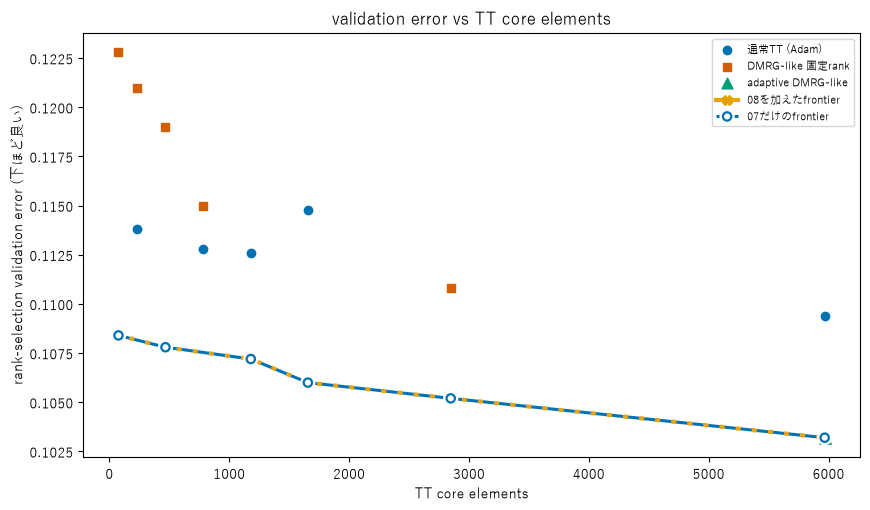

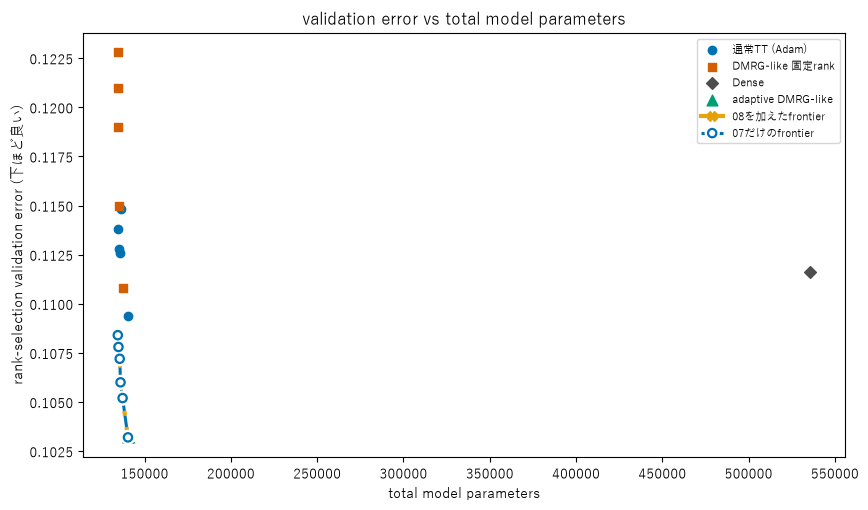

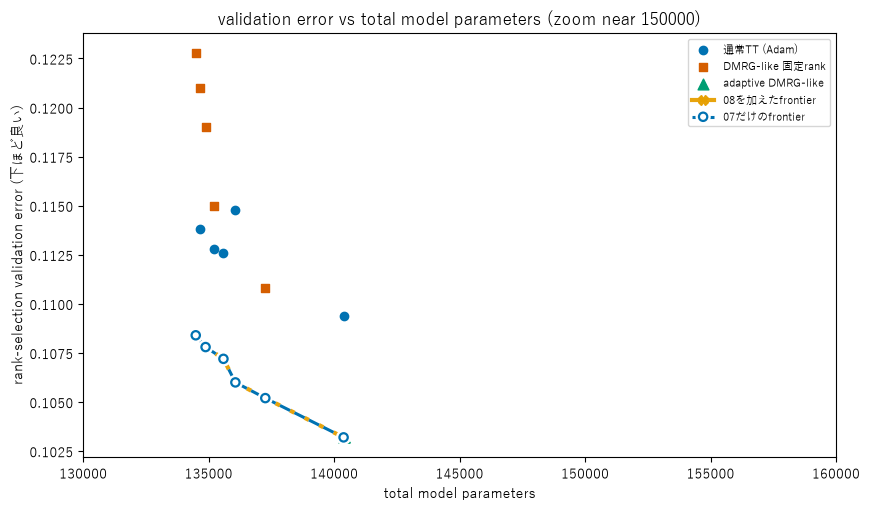

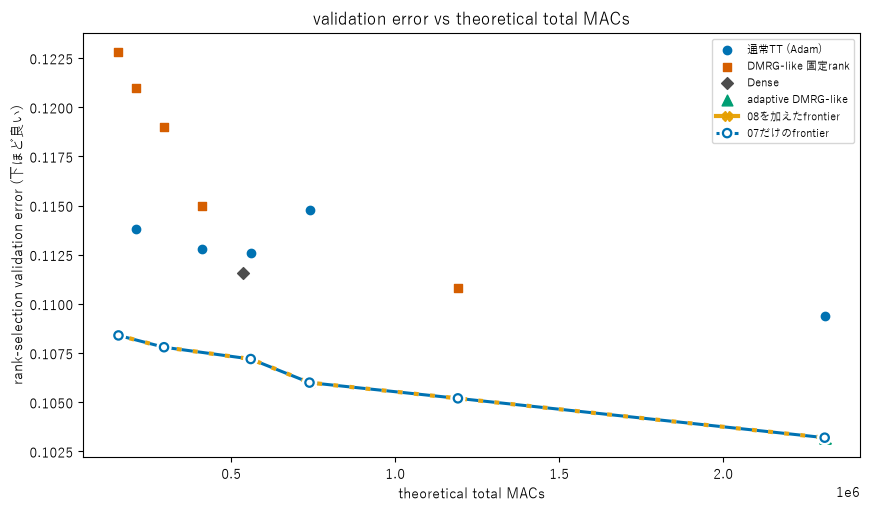

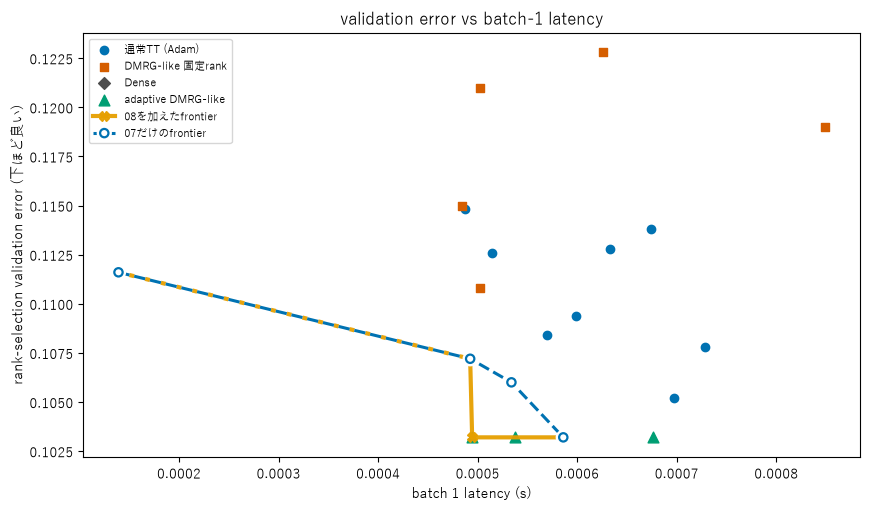

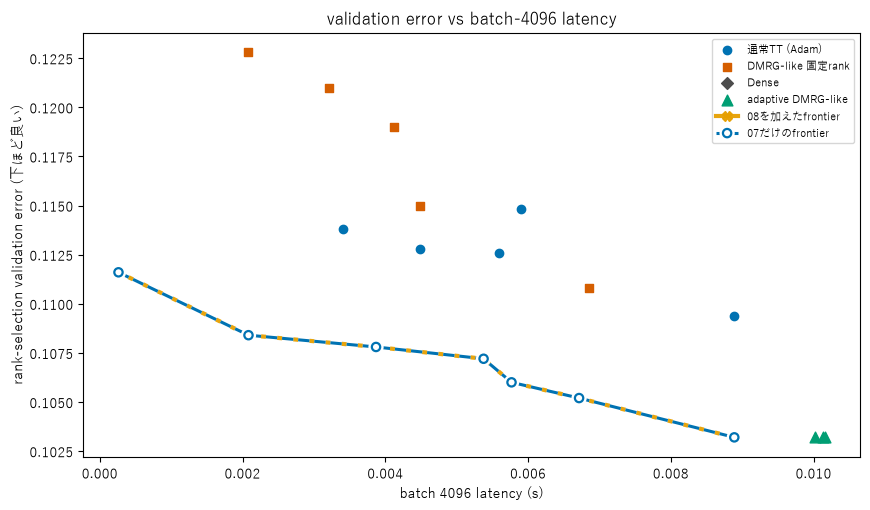

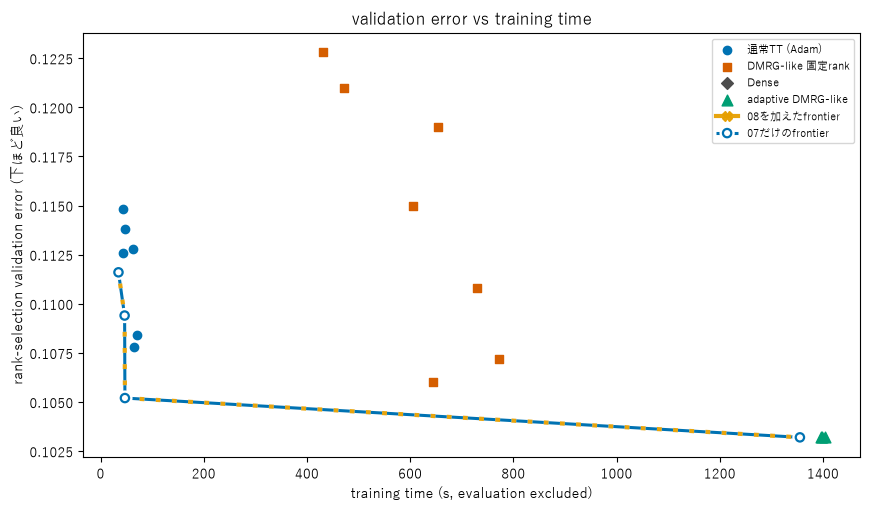

最後の図: データ自体はあります。3閾値とも bond rank が学習中に一度も変わらず、水平線（bond1=8, bond2-5=12）だけになるため『線が無い』ように見えていました。


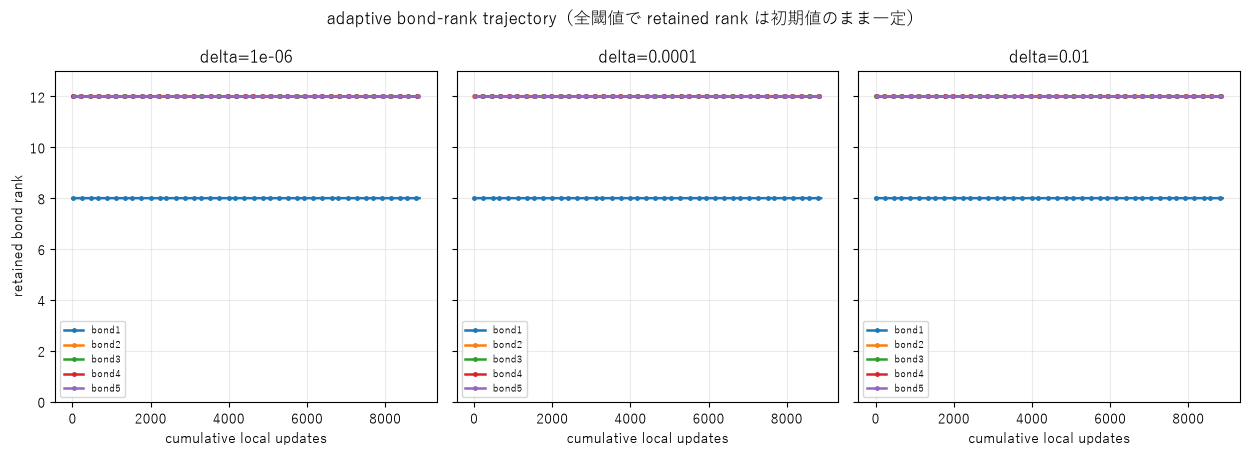

In [34]:
display_comparison()


## 結果を読むときの項目

学習結果ができたあとで、次を分ける。

- 07 の候補に支配されない新しい点
- 07 の候補を誤差と費用の両方で支配する点
- 精度だけ改善した点
- 圧縮だけ改善した点
- 学習時間では不利な点

parameter 数、理論 MACs、latency、学習時間は別々の frontier である。latency は 07 と同じ warmup 20、繰り返し 100、batch 1 と 4096 の中央値である。GPU 名が違う場合は同じ latency として比較しない。

ここには、まだ走っていない実験の結論は書かない。
